# Exercise 1

## Part 1 — Two-dimensional data

We fit a histogram, a single Gaussian, a Gaussian mixture and a Gaussian KDE to
make_moons data with noise **0.1**. The labels are discarded throughout.

The four models and MMD are implemented below using only NumPy. This notebook
also contains the experiments, plots and discussion; run it from top to bottom.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.datasets import make_moons

SEED = 17
NOISE = 0.1
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
np.set_printoptions(precision=4, suppress=True)


def moons(n, seed):
    X, _ = make_moons(n_samples=n, noise=NOISE, random_state=seed)
    return X


def make_model(name, parameter, seed=SEED):
    if name == 'Histogram':
        return Histogram2D(bins=parameter)
    if name == 'Single Gaussian':
        return SingleGaussian()
    if name == 'GMM':
        return GaussianMixture(n_components=parameter, random_state=seed)
    return GaussianKDE(bandwidth=parameter)


X_ref = moons(1200, SEED)
X_test = moons(500, SEED + 1)
print('Reference training set:', X_ref.shape, '| independent test set:', X_test.shape)

Reference training set: (1200, 2) | independent test set: (500, 2)


## About models' learning

Fitting returns the model itself; scoring returns **log
density**, following sklearn's convention.

**Histogram:** count points in rectangular bins and divide each bin's mass
  by its area. Sampling first chooses a bin by its mass, then a uniform point
  inside it. bins is the number of bins **per axis**: more bins means smaller bins.

**Single Gaussian:** estimate the mean and full covariance by maximum likelihood,
  dividing the covariance by $n$, rather than $n-1$.

**GMM:** alternate responsibility calculations (E-step) and weighted parameter
  updates (M-step). We use k-means++ seeds and keep the best of three starts.
  Convergence compares consecutive, finite mean log likelihoods. A one-component
  mixture uses the same EM algorithm as every other mixture.
  
**KDE:** put an isotropic Gaussian of covariance $b^2I$ at every training point.
  Sampling chooses a training point uniformly and adds Gaussian noise of standard
  deviation $b$.

The Gaussian models use a $10^{-6}I$ covariance regularizer. Log-sum-exp keeps
mixture and KDE scores stable without changing their density formulas.

In [ ]:
def _squared_distances(X, Y):
    distances = (
        np.sum(X**2, axis=1)[:, None]
        + np.sum(Y**2, axis=1)[None, :]
        - 2 * X @ Y.T
    )
    return np.maximum(distances, 0)


def _logsumexp(values):
    largest = values.max(axis=1, keepdims=True)
    return largest[:, 0] + np.log(np.exp(values - largest).sum(axis=1))


def _log_gaussian(X, mean, covariance):
    chol = np.linalg.cholesky(covariance)
    centered = np.linalg.solve(chol, (X - mean).T)
    log_det = 2 * np.log(np.diag(chol)).sum()
    return -0.5 * (
        X.shape[1] * np.log(2 * np.pi)
        + log_det
        + np.sum(centered**2, axis=0)
    )


class Histogram2D:
    def __init__(self, bins=16):
        self.bins = bins

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        bins = (self.bins, self.bins) if np.isscalar(self.bins) else self.bins
        self.edges_ = [
            np.linspace(X[:, axis].min(), X[:, axis].max(), bins[axis] + 1)
            for axis in range(2)
        ]
        self.counts_ = np.zeros(bins)
        indices = self._bin_indices(X)
        np.add.at(self.counts_, (indices[:, 0], indices[:, 1]), 1)
        self.probabilities_ = self.counts_ / len(X)
        widths_x, widths_y = [np.diff(edges) for edges in self.edges_]
        self.bin_areas_ = widths_x[:, None] * widths_y[None, :]
        self.density_ = self.probabilities_ / self.bin_areas_
        self.n_features_in_ = X.shape[1]
        return self

    def _bin_indices(self, X):
        return np.column_stack([
            np.clip(
                np.searchsorted(edges, X[:, axis], side="right") - 1,
                0,
                len(edges) - 2,
            )
            for axis, edges in enumerate(self.edges_)
        ])

    def score_samples(self, X):
        X = np.asarray(X, dtype=float)
        indices = self._bin_indices(X)
        inside = np.all([
            (X[:, axis] >= edges[0]) & (X[:, axis] <= edges[-1])
            for axis, edges in enumerate(self.edges_)
        ], axis=0)
        density = self.density_[indices[:, 0], indices[:, 1]]
        log_density = np.full(len(X), -np.inf)
        occupied = inside & (density > 0)
        log_density[occupied] = np.log(density[occupied])
        return log_density

    def sample(self, n_samples=1, random_state=None):
        rng = np.random.default_rng(random_state)
        chosen = rng.choice(
            self.probabilities_.size,
            size=n_samples,
            p=self.probabilities_.ravel(),
        )
        indices = np.column_stack(np.unravel_index(chosen, self.counts_.shape))
        lower = np.column_stack([
            edges[indices[:, axis]] for axis, edges in enumerate(self.edges_)
        ])
        upper = np.column_stack([
            edges[indices[:, axis] + 1] for axis, edges in enumerate(self.edges_)
        ])
        return rng.uniform(lower, upper)


class SingleGaussian:
    def __init__(self, reg_covar=1e-6):
        self.reg_covar = reg_covar

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        centered = X - self.mean_
        self.n_features_in_ = X.shape[1]
        # Maximum likelihood divides by n, rather than the unbiased n - 1.
        self.covariance_ = centered.T @ centered / len(X)
        self.covariance_ += self.reg_covar * np.eye(self.n_features_in_)
        return self

    def score_samples(self, X):
        return _log_gaussian(np.asarray(X, dtype=float), self.mean_, self.covariance_)

    def sample(self, n_samples=1, random_state=None):
        return np.random.default_rng(random_state).multivariate_normal(
            self.mean_, self.covariance_, size=n_samples
        )


class GaussianMixture:
    def __init__(
        self,
        n_components=2,
        max_iter=400,
        tol=1e-5,
        reg_covar=1e-6,
        n_init=3,
        random_state=None,
    ):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.reg_covar = reg_covar
        self.n_init = n_init
        self.random_state = random_state

    def _initialize(self, X, rng):
        means = [X[rng.integers(len(X))]]
        nearest = np.sum((X - means[0])**2, axis=1)
        for _ in range(1, self.n_components):
            means.append(X[rng.choice(len(X), p=nearest / nearest.sum())])
            nearest = np.minimum(nearest, np.sum((X - means[-1])**2, axis=1))
        self.means_ = np.array(means)
        centered = X - X.mean(axis=0)
        covariance = centered.T @ centered / len(X)
        covariance += self.reg_covar * np.eye(self.n_features_in_)
        self.covariances_ = np.repeat(covariance[None], self.n_components, axis=0)
        self.weights_ = np.full(self.n_components, 1 / self.n_components)

    def _log_joint(self, X):
        return np.column_stack([
            np.log(weight) + _log_gaussian(X, mean, covariance)
            for weight, mean, covariance in zip(
                self.weights_, self.means_, self.covariances_
            )
        ])

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        rng = np.random.default_rng(self.random_state)
        best_likelihood = -np.inf

        for _ in range(self.n_init):
            self._initialize(X, rng)
            log_joint = self._log_joint(X)
            log_density = _logsumexp(log_joint)
            history = [log_density.mean()]
            converged = False

            for iteration in range(1, self.max_iter + 1):
                responsibilities = np.exp(log_joint - log_density[:, None]) # expectation step

                counts = np.maximum(responsibilities.sum(axis=0), np.finfo(float).eps) # maximization step
                self.weights_ = counts / counts.sum()
                self.means_ = responsibilities.T @ X / counts[:, None]
                for component in range(self.n_components):
                    centered = X - self.means_[component]
                    covariance = (centered.T * responsibilities[:, component]) @ centered
                    covariance /= counts[component]
                    covariance += self.reg_covar * np.eye(self.n_features_in_)
                    self.covariances_[component] = covariance

                log_joint = self._log_joint(X)
                log_density = _logsumexp(log_joint)
                history.append(log_density.mean())
                if abs(history[-1] - history[-2]) < self.tol:
                    converged = True
                    break

            # Expectation - Maximization finds local optima
            if history[-1] > best_likelihood:
                best_likelihood = history[-1]
                best_parameters = (
                    self.weights_.copy(), self.means_.copy(), self.covariances_.copy()
                )
                self.n_iter_ = iteration
                self.converged_ = converged
                self.lower_bounds_ = np.array(history)

        self.weights_, self.means_, self.covariances_ = best_parameters
        self.lower_bound_ = best_likelihood
        return self

    def score_samples(self, X):
        return _logsumexp(self._log_joint(np.asarray(X, dtype=float)))

    def sample(self, n_samples=1, random_state=None):
        rng = np.random.default_rng(random_state)
        if self.n_components == 1:
            return rng.multivariate_normal(
                self.means_[0], self.covariances_[0], size=n_samples
            )
        chosen = rng.choice(self.n_components, size=n_samples, p=self.weights_)
        samples = np.empty((n_samples, self.n_features_in_))
        for component in range(self.n_components):
            mask = chosen == component
            samples[mask] = rng.multivariate_normal(
                self.means_[component], self.covariances_[component], size=mask.sum()
            )
        return samples


class GaussianKDE:
    def __init__(self, bandwidth=0.12):
        self.bandwidth = bandwidth

    def fit(self, X):
        self.X_ = np.array(X, dtype=float, copy=True)
        self.n_features_in_ = self.X_.shape[1]
        return self

    def score_samples(self, X):
        X = np.asarray(X, dtype=float)
        normalizer = np.log(len(self.X_)) + self.n_features_in_ * np.log(
            self.bandwidth * np.sqrt(2 * np.pi)
        )
        log_density = np.empty(len(X))

        for start in range(0, len(X), 256):
            query = X[start:start + 256]
            log_kernels = -_squared_distances(query, self.X_) / (2 * self.bandwidth**2)
            log_density[start:start + len(query)] = _logsumexp(log_kernels) - normalizer
        return log_density

    def sample(self, n_samples=1, random_state=None):
        rng = np.random.default_rng(random_state)
        centers = self.X_[rng.integers(len(self.X_), size=n_samples)]
        return centers + rng.normal(
            scale=self.bandwidth, size=(n_samples, self.n_features_in_)
        )


def mmd2(X, Y, bandwidth=0.5, kernel="se"):
    X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float)

    def kernel_matrix(A, B):
        scaled = _squared_distances(A, B) / bandwidth**2
        if kernel == "se":
            return np.exp(-scaled)
        return 1 / np.sqrt(1 + scaled)

    Kxx = kernel_matrix(X, X)
    Kyy = kernel_matrix(Y, Y)
    Kxy = kernel_matrix(X, Y)
    n, m = len(X), len(Y)
    within_x = (Kxx.sum() - np.trace(Kxx)) / (n * (n - 1))
    within_y = (Kyy.sum() - np.trace(Kyy)) / (m * (m - 1))
    return float(within_x + within_y - 2 * Kxy.mean())

In [6]:
# Check the required equivalence using an actual one-component EM fit.
gaussian = SingleGaussian().fit(X_ref)
gmm_one = GaussianMixture(n_components=1, random_state=SEED).fit(X_ref)
np.testing.assert_allclose(gaussian.mean_, gmm_one.means_[0])
np.testing.assert_allclose(gaussian.covariance_, gmm_one.covariances_[0])
np.testing.assert_allclose(gaussian.score_samples(X_test), gmm_one.score_samples(X_test))
np.testing.assert_allclose(gaussian.sample(50, random_state=1), gmm_one.sample(50, random_state=1))

gmm_demo = GaussianMixture(n_components=8, random_state=SEED).fit(X_ref)
print('Single Gaussian and GMM(1): matching parameters, log densities and seeded samples.')
print(f'GMM(8): {gmm_demo.n_iter_} EM iterations, converged={gmm_demo.converged_}')
print(f'Mean training log density: {gmm_demo.lower_bounds_[0]:.3f} -> {gmm_demo.lower_bound_:.3f}')

Single Gaussian and GMM(1): matching parameters, log densities and seeded samples.
GMM(8): 155 EM iterations, converged=True
Mean training log density: -2.101 -> -1.028


## Choosing the bandwidth of MML Kernel

We calculate the unbiased MMD score using fast matrix operations instead of loops, applying the two kernels from the exercise and ignoring self-comparisons along the diagonal.

First, we test different kernel bandwidths (h) while keeping the generated datasets fixed (note that this is separate from the KDE model bandwidth b). The independent moons sample acts as a baseline to show the natural variation caused by using a finite sample size.

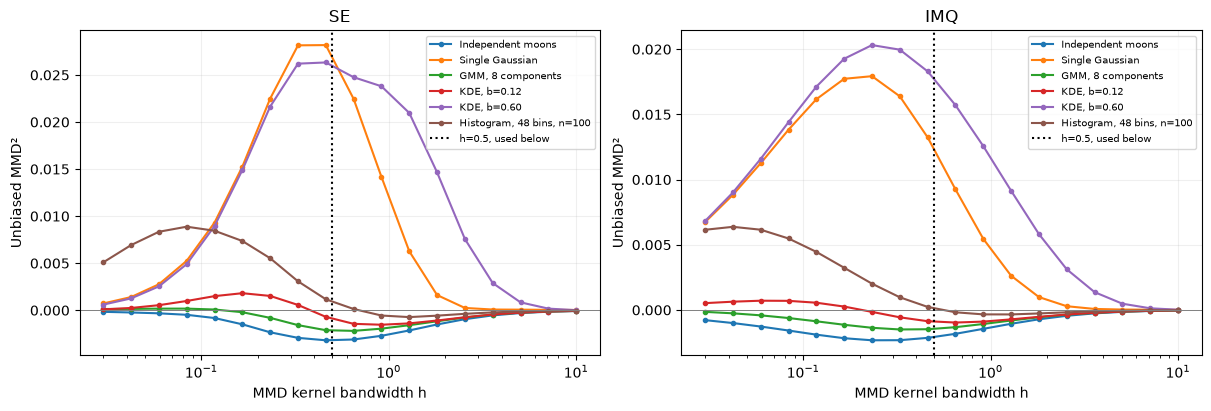

In [7]:
bandwidth_models = {
    'Independent moons': moons(len(X_test), SEED + 2),
    'Single Gaussian': gaussian.sample(len(X_test), random_state=SEED + 3),
    'GMM, 8 components': gmm_demo.sample(len(X_test), random_state=SEED + 3),
    'KDE, b=0.12': GaussianKDE(0.12).fit(X_ref).sample(len(X_test), random_state=SEED + 3),
    'KDE, b=0.60': GaussianKDE(0.60).fit(X_ref).sample(len(X_test), random_state=SEED + 3),
    'Histogram, 48 bins, n=100': Histogram2D(48).fit(X_ref[:100]).sample(len(X_test), random_state=SEED + 3),
}
metric_bandwidths = np.geomspace(0.03, 10, 18)
bandwidth_results = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, kernel in zip(axes, ('se', 'imq')):
    for name, generated in bandwidth_models.items():
        values = [mmd2(X_test, generated, bandwidth=h, kernel=kernel) for h in metric_bandwidths]
        bandwidth_results[kernel, name] = values
        ax.plot(metric_bandwidths, values, '.-', label=name)
    ax.axhline(0, color='grey', linewidth=0.7)
    ax.axvline(0.5, color='black', linestyle=':', label='h=0.5, used below')
    ax.set(xscale='log', xlabel='MMD kernel bandwidth h', ylabel='Unbiased MMD²', title=kernel.upper())
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7.5)
plt.show()

## Hyperparams and training set size

We compare **100, 400 and 1200 training points**, with three independent repeats.
Each repeat has a new training set and an independent 500-point test set. Every
model is evaluated with 500 generated points. Models within a repeat share the
test set, making the comparisons less sensitive to which test points were drawn.

The sweep above shows that moderate MMD bandwidths distinguish the curved models
from the Gaussian baseline. We use **h=0.5 for both kernels** below. Absolute
values from different kernels are shown separately; they are not averaged into
a single score. Error bars show **one standard deviation across three repeats**,
including training and sampling variation. Small negative estimates are kept.

In [8]:
train_sizes = [100, 400, 1200]
parameter_grid = {
    'Histogram': [4, 8, 16, 32, 48],
    'Single Gaussian': [1],
    'GMM': [1, 2, 4, 8, 12],
    'KDE': [0.04, 0.08, 0.12, 0.20, 0.35, 0.60],
}
N_REPEATS = 3
N_EVAL = 500
MMD_BANDWIDTH = 0.5
results = []
em_iterations = []
em_converged = []

for repeat in range(N_REPEATS):
    seed = SEED + 10000 * (repeat + 1)
    test = moons(N_EVAL, seed)
    for n_train in train_sizes:
        train = moons(n_train, seed + n_train)
        for name, parameters in parameter_grid.items():
            for parameter in parameters:
                model = make_model(name, parameter, seed=seed + 1).fit(train)
                generated = model.sample(N_EVAL, random_state=seed + 2)
                row = dict(model=name, parameter=parameter, n_train=n_train, repeat=repeat)
                for kernel in ('se', 'imq'):
                    row[kernel] = mmd2(test, generated, bandwidth=MMD_BANDWIDTH, kernel=kernel)
                results.append(row)
                if name == 'GMM':
                    em_iterations.append(model.n_iter_)
                    em_converged.append(model.converged_)
    print(f'Repeat {repeat + 1}/{N_REPEATS} finished.')

summary = {}
for name, parameters in parameter_grid.items():
    for n_train in train_sizes:
        for parameter in parameters:
            rows = [r for r in results if (r['model'], r['n_train'], r['parameter']) == (name, n_train, parameter)]
            for kernel in ('se', 'imq'):
                scores = [r[kernel] for r in rows]
                summary[name, n_train, parameter, kernel] = (np.mean(scores), np.std(scores, ddof=1))

print(f'\n{len(results)} fitted models; each evaluated with both MMD kernels.')
print(f'GMM iterations: {min(em_iterations)} to {max(em_iterations)}; converged: {sum(em_converged)}/{len(em_converged)}')
print('\nAt n=1200 (mean ± standard deviation):')
print(f"{'Model':<17} {'Parameter':>9} {'SE MMD²':>20} {'IMQ MMD²':>20}")
for name, parameters in parameter_grid.items():
    for parameter in parameters:
        se_mean, se_std = summary[name, 1200, parameter, 'se']
        imq_mean, imq_std = summary[name, 1200, parameter, 'imq']
        print(f'{name:<17} {parameter:>9g} {se_mean:>9.5f} ± {se_std:.5f} {imq_mean:>9.5f} ± {imq_std:.5f}')

Repeat 1/3 finished.
Repeat 2/3 finished.
Repeat 3/3 finished.

153 fitted models; each evaluated with both MMD kernels.
GMM iterations: 2 to 299; converged: 45/45

At n=1200 (mean ± standard deviation):
Model             Parameter              SE MMD²             IMQ MMD²
Histogram                 4   0.00781 ± 0.00115   0.00296 ± 0.00052
Histogram                 8   0.00015 ± 0.00064  -0.00049 ± 0.00040
Histogram                16  -0.00138 ± 0.00063  -0.00117 ± 0.00031
Histogram                32  -0.00195 ± 0.00037  -0.00148 ± 0.00016
Histogram                48  -0.00136 ± 0.00019  -0.00116 ± 0.00006
Single Gaussian           1   0.02578 ± 0.00156   0.01131 ± 0.00116
GMM                       1   0.02578 ± 0.00156   0.01131 ± 0.00116
GMM                       2   0.01339 ± 0.00249   0.00463 ± 0.00138
GMM                       4   0.00215 ± 0.00066   0.00013 ± 0.00023
GMM                       8  -0.00113 ± 0.00071  -0.00095 ± 0.00040
GMM                      12  -0.00094 ± 0.0006

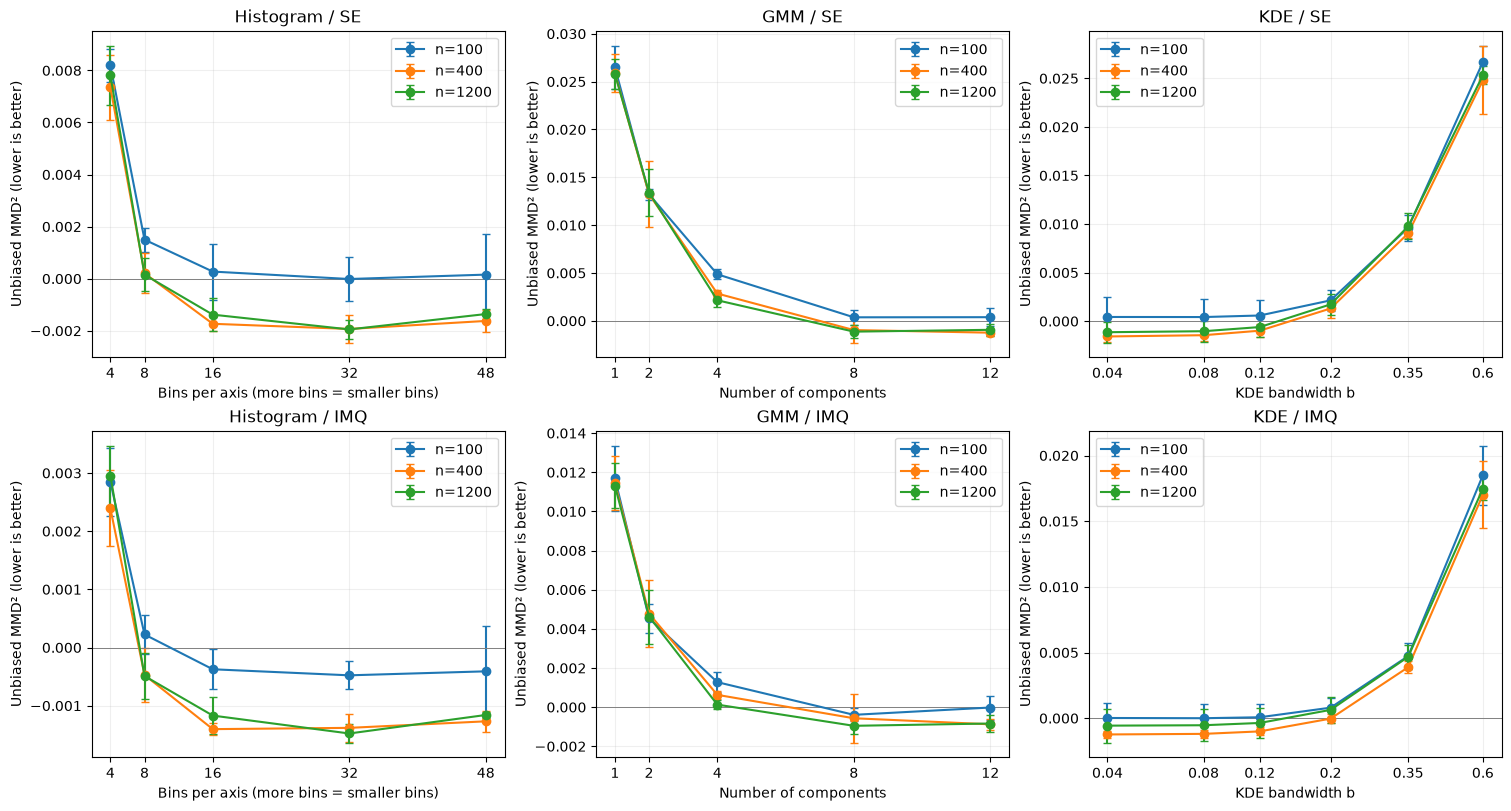

In [9]:
families = ['Histogram', 'GMM', 'KDE']
labels = ['Bins per axis (more bins = smaller bins)', 'Number of components', 'KDE bandwidth b']
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for row, kernel in enumerate(('se', 'imq')):
    for col, (name, xlabel) in enumerate(zip(families, labels)):
        ax = axes[row, col]
        parameters = parameter_grid[name]
        for n_train in train_sizes:
            values = [summary[name, n_train, parameter, kernel] for parameter in parameters]
            means, stds = np.array(values).T
            ax.errorbar(parameters, means, yerr=stds, marker='o', capsize=3, label=f'n={n_train}')
        ax.axhline(0, color='grey', linewidth=0.7)
        ax.set(title=f'{name} / {kernel.upper()}', xlabel=xlabel, ylabel='Unbiased MMD² (lower is better)')
        if name == 'KDE':
            ax.set_xscale('log')
            ax.set_xticks(parameters, labels=[f'{p:g}' for p in parameters])
            ax.minorticks_off()
        else:
            ax.set_xticks(parameters)
        ax.grid(alpha=0.2)
        ax.legend()
plt.show()

To see training size more directly, the next plot fixes a reasonable setting for
each model. Keeping hyperparameters fixed avoids selecting a fresh winner from
the same test data at every training size. These are illustrative settings,
rather than the result of a separate validation procedure.

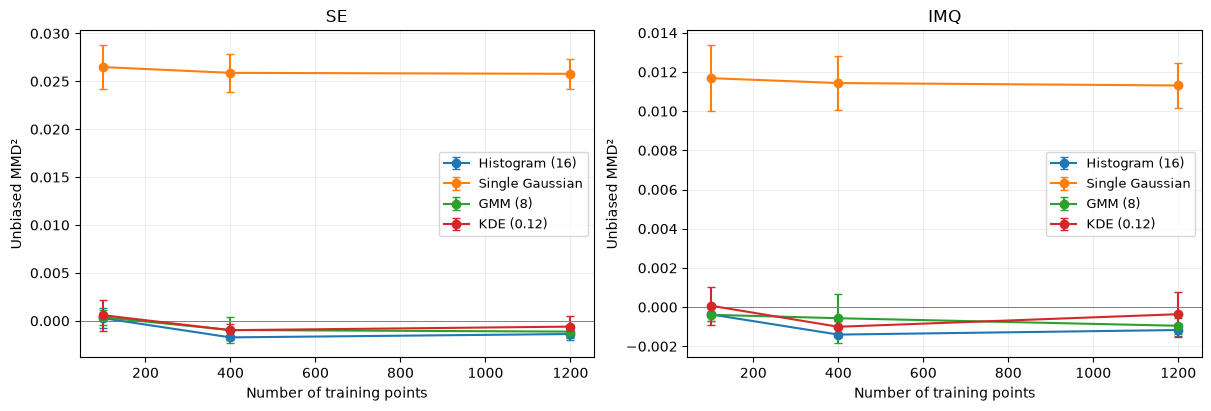

In [10]:
fixed_settings = {'Histogram': 16, 'Single Gaussian': 1, 'GMM': 8, 'KDE': 0.12}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, kernel in zip(axes, ('se', 'imq')):
    for name, parameter in fixed_settings.items():
        values = [summary[name, n, parameter, kernel] for n in train_sizes]
        means, stds = np.array(values).T
        label = name if name == 'Single Gaussian' else f'{name} ({parameter})'
        ax.errorbar(train_sizes, means, yerr=stds, marker='o', capsize=3, label=label)
    ax.axhline(0, color='grey', linewidth=0.7)
    ax.set(title=kernel.upper(), xlabel='Number of training points', ylabel='Unbiased MMD²')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
plt.show()

## Representative densities and generated data

Each pair of plots shows the model's estimated density on the left and 900 generated points on the right. We also draw grid lines for the histograms and ellipses for the Gaussian models to show how they fit the data.

We included both good and overly simple model settings for comparison. For example, one histogram is trained on only 100 points to show what happens when bins are empty.

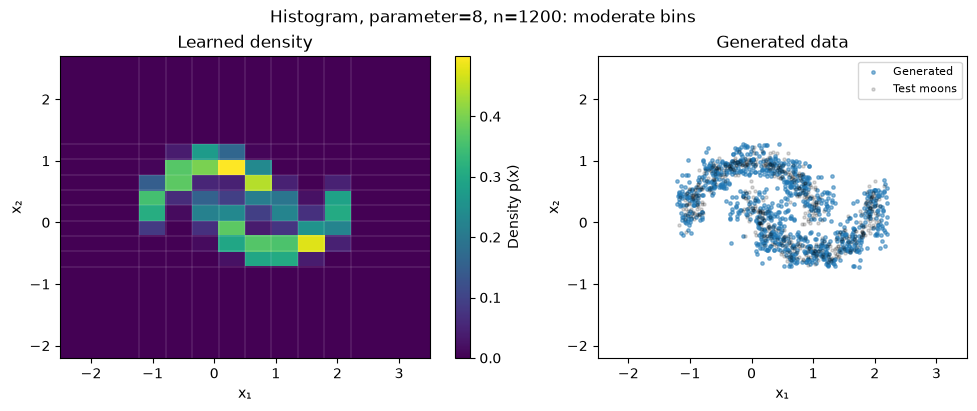

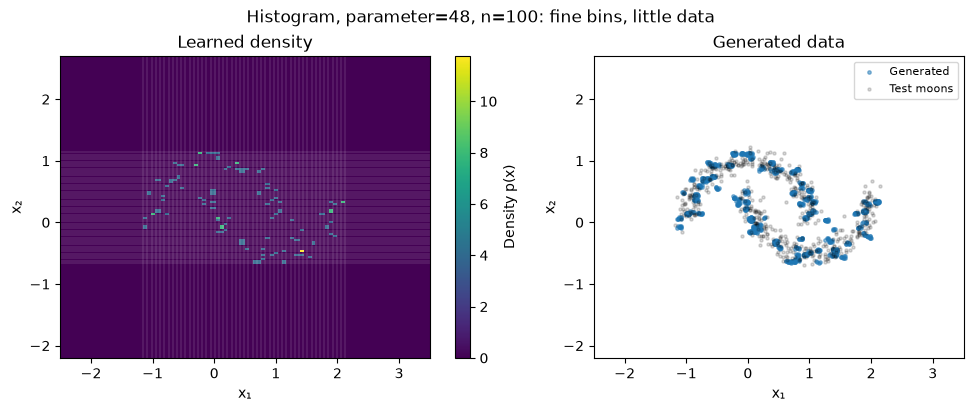

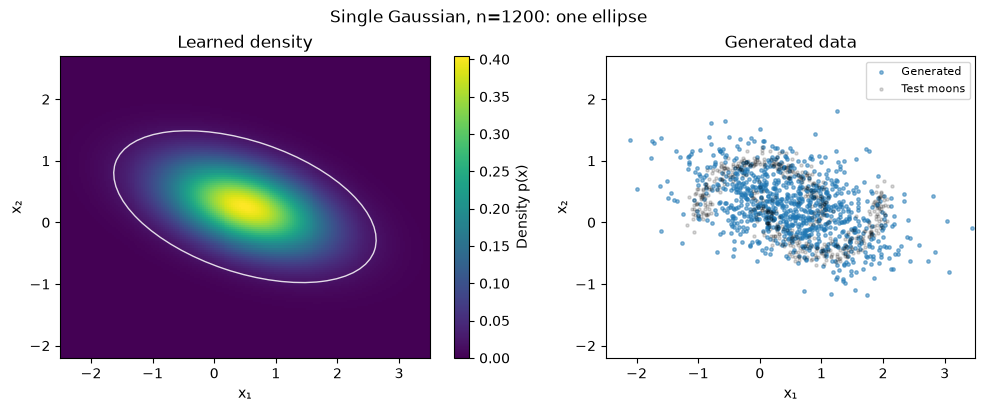

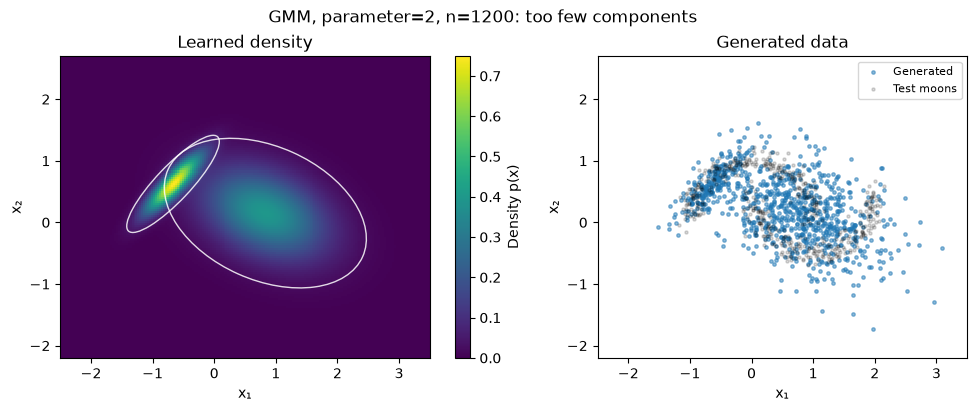

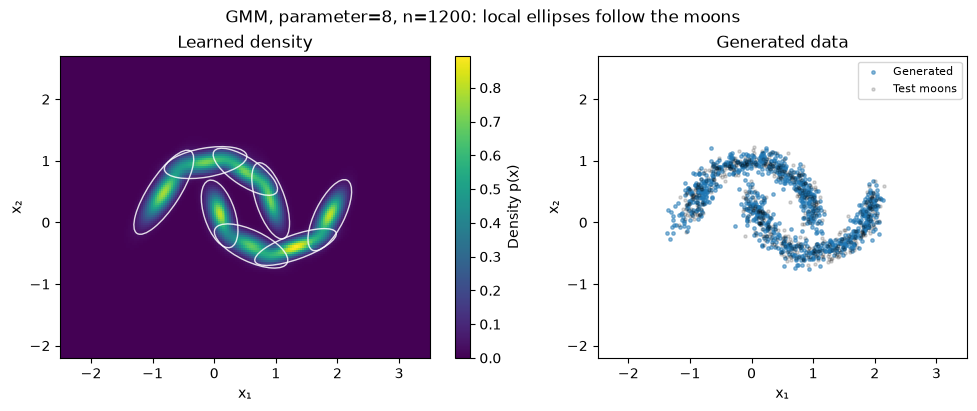

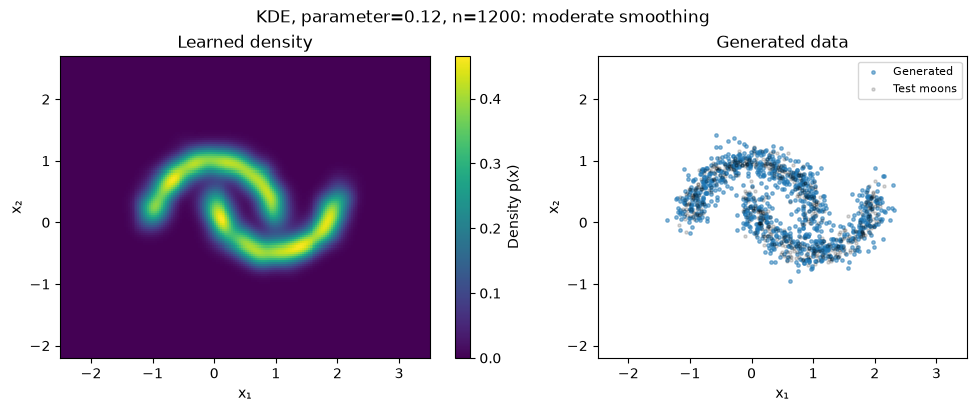

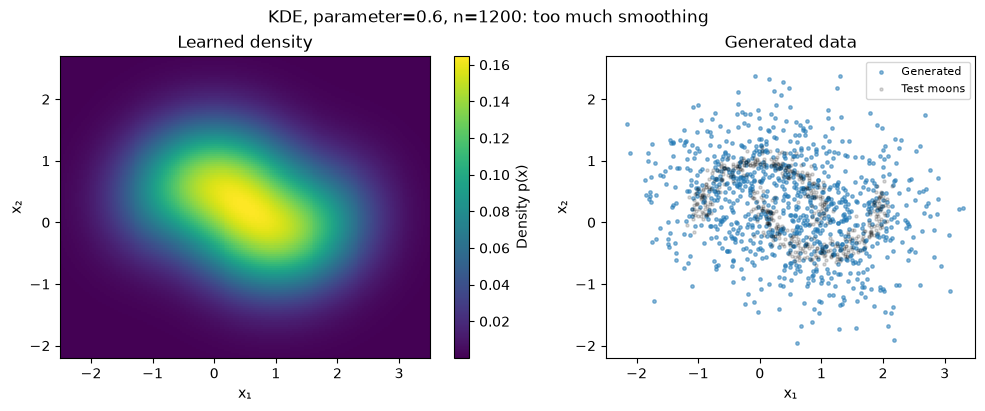

In [11]:
def add_ellipse(ax, mean, covariance, color='white'):
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    major = eigenvectors[:, -1]
    angle = np.degrees(np.arctan2(major[1], major[0]))
    width, height = 2 * np.sqrt(5.991 * eigenvalues[::-1])
    ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False,
                         edgecolor=color, linewidth=1, alpha=0.85))


examples = [
    ('Histogram', 8, 1200, 'moderate bins'),
    ('Histogram', 48, 100, 'fine bins, little data'),
    ('Single Gaussian', 1, 1200, 'one ellipse'),
    ('GMM', 2, 1200, 'too few components'),
    ('GMM', 8, 1200, 'local ellipses follow the moons'),
    ('KDE', 0.12, 1200, 'moderate smoothing'),
    ('KDE', 0.60, 1200, 'too much smoothing'),
]
xx, yy = np.meshgrid(np.linspace(-2.5, 3.5, 190), np.linspace(-2.2, 2.7, 150))
grid = np.column_stack([xx.ravel(), yy.ravel()])

for index, (name, parameter, n_train, description) in enumerate(examples):
    model = make_model(name, parameter).fit(X_ref[:n_train])
    density = np.exp(model.score_samples(grid)).reshape(xx.shape)
    generated = model.sample(900, random_state=SEED + index)
    fig, (ax_density, ax_sample) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    heatmap = ax_density.pcolormesh(xx, yy, density, shading='auto', cmap='viridis', rasterized=True)
    fig.colorbar(heatmap, ax=ax_density, label='Density p(x)')
    ax_sample.scatter(generated[:, 0], generated[:, 1], s=6, alpha=0.5, label='Generated')
    ax_sample.scatter(X_test[:, 0], X_test[:, 1], s=5, c='black', alpha=0.15, label='Test moons')
    if isinstance(model, Histogram2D):
        for edge in model.edges_[0]:
            ax_density.axvline(edge, color='white', linewidth=0.3, alpha=0.45)
        for edge in model.edges_[1]:
            ax_density.axhline(edge, color='white', linewidth=0.3, alpha=0.45)
    elif isinstance(model, GaussianMixture):
        for mean, covariance in zip(model.means_, model.covariances_):
            add_ellipse(ax_density, mean, covariance)
    elif isinstance(model, SingleGaussian):
        add_ellipse(ax_density, model.mean_, model.covariance_)

    parameter_text = '' if name == 'Single Gaussian' else f', parameter={parameter}'
    fig.suptitle(f'{name}{parameter_text}, n={n_train}: {description}')
    ax_density.set_title('Learned density')
    ax_sample.set_title('Generated data')
    ax_sample.legend(fontsize=8)
    for ax in (ax_density, ax_sample):
        ax.axis('equal')
        ax.set_aspect('equal', adjustable='box')
        ax.set(xlim=(-2.5, 3.5), ylim=(-2.2, 2.7), xlabel='x₁', ylabel='x₂')
    plt.show()

## Findings

**Histogram:** at n=1200, moving from 4 to 32 bins per axis reduces mean SE
  MMD² from about **0.0078 to -0.0019**. The coarse model spreads mass across
  the moon boundaries. Finer bins follow the shape better, but the 48-bin model
  fitted to 100 points has many empty cells and generates tiny clusters.
  Its broad-scale MMD can still be small: a low score at one scale does not
  guarantee a smooth or locally accurate density.

**Single Gaussian:** SE MMD² stays around **0.026**, even with more data.
  The fitted ellipse fills the gap between the moons. More observations cannot
  remove this restriction of the model family. GMM(1) matches it, including
  samples generated with the same seed.

**GMM:** 2 components still blur the curved shapes. With 8 components, mean
  SE MMD² is about **-0.0011** at n=1200, and the ellipses visibly follow the
  arcs. Moving to 12 components gives no consistent improvement across kernels
  and repeats. The finite-sample variation is comparable to the differences
  between the better mixtures, so we cannot claim a clear winner there.

**KDE:** bandwidths **0.04–0.12** give similar small scores in this experiment;
  b=0.12 makes a smooth density in the plots. At **b=0.60**, SE MMD² rises to
  about **0.0253** and IMQ MMD² to **0.0175**: too much Gaussian noise washes
  out the moons. A very narrow bandwidth can preserve global shape while
  producing a spiky density, especially with little training data.

**Training size:** for the flexible settings, the main improvement is from
  100 to 400 points. The difference between 400 and 1200 is smaller and not
  consistently ordered with only three repeats. The Gaussian baseline barely
  improves because its dominant error is its shape assumption.

**MMD bandwidth:** moderate h values separate the Gaussian and oversmoothed
  KDE from the better models. At very large h, kernels become almost constant
  and the scores approach zero. As h tends to zero, similarities between
  distinct points also vanish, so a tiny score can again be uninformative.
  The sparse histogram illustrates why local artifacts also need the density
  plots and smaller-scale comparisons. SE and IMQ have different numerical
  scales, so their raw scores should not be averaged.

Negative numbers are possible for the unbiased estimator; they do not mean the
population discrepancy is negative or that a fitted model beats the true
distribution. These are exploratory comparisons, without a separate validation
set for tuning hyperparameters. The plotted standard deviations describe only
three repeats, so close rankings should be treated cautiously.

# Part 2 — Higher-dimensional data

We now repeat the experiments on the digits dataset (1797 images of 8×8 = 64 pixels). We scale the pixel values by dividing by 16 and fit all models directly in the 64-dimensional space without PCA.

We use scikit-learn for the Single Gaussian, GMM, and KDE models, and use the provided density_forest.py file instead of a regular histogram.

For the density forest, we add regularization to the entropy calculation to handle constant background pixels, make sure splits respect the minimum leaf size, and weight child entropies by their size. Fixed seeds are used to keep results reproducible.

In [12]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture as SklearnGMM
from sklearn.neighbors import KernelDensity as SklearnKDE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from scipy.stats import chisquare
from threadpoolctl import threadpool_limits

from density_forest import DensityForest

digits = load_digits()
digit_X = digits.data / 16.0
digit_y = digits.target
digit_train_ids, digit_holdout_ids = train_test_split(
    np.arange(len(digit_X)), test_size=0.30, stratify=digit_y, random_state=SEED
)
digit_test_ids, digit_reference_ids = train_test_split(
    digit_holdout_ids, test_size=0.5, stratify=digit_y[digit_holdout_ids], random_state=SEED + 1
)
digit_train, digit_train_y = digit_X[digit_train_ids], digit_y[digit_train_ids]
digit_test, digit_test_y = digit_X[digit_test_ids], digit_y[digit_test_ids]
digit_reference = digit_X[digit_reference_ids]
print(f'Training pool: {digit_train.shape}; test: {digit_test.shape}; real-data reference: {digit_reference.shape}')
print('Training labels are used for stratified subsets and the classifier, not for fitting density models.')

Training pool: (1257, 64); test: (270, 64); real-data reference: (270, 64)
Training labels are used for stratified subsets and the classifier, not for fitting density models.


## A classifier to evaluate recognisability

The Random Forest classifier is trained on **original training images only**.
Its accuracy and confusion matrix are evaluated on held-out real images before
we apply it to generated images. A maximum predicted probability of at least
**0.60** is our fixed confidence criterion. We report its coverage and accuracy
on real test images so the threshold has a reference.

Confidence is a practical proxy for recognisability, not proof that a generated
image is a valid digit. The image grids remain part of the evaluation.

Classifier accuracy on held-out real digits: 98.52%
Real test images with confidence ≥ 0.60: 81.85%
Accuracy within that confident subset: 100.00%


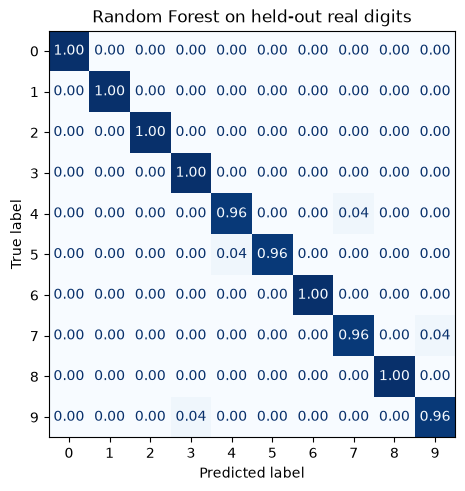

In [13]:
digit_classifier = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)
digit_classifier.fit(digit_train, digit_train_y)
digit_real_probabilities = digit_classifier.predict_proba(digit_test)
digit_real_predictions = digit_classifier.classes_[digit_real_probabilities.argmax(axis=1)]
DIGIT_CONFIDENCE = 0.60
digit_real_confident = digit_real_probabilities.max(axis=1) >= DIGIT_CONFIDENCE
print(f'Classifier accuracy on held-out real digits: {accuracy_score(digit_test_y, digit_real_predictions):.2%}')
print(f'Real test images with confidence ≥ {DIGIT_CONFIDENCE:.2f}: {digit_real_confident.mean():.2%}')
print(f'Accuracy within that confident subset: {accuracy_score(digit_test_y[digit_real_confident], digit_real_predictions[digit_real_confident]):.2%}')

fig, ax = plt.subplots(figsize=(5.5, 4.8), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(
    digit_test_y, digit_real_predictions, labels=np.arange(10),
    normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=ax
)
ax.set_title('Random Forest on held-out real digits')
plt.show()

## Model settings and MMD scale

We vary training size (200, 600, 1200), the forest's minimum leaf size, the number
of GMM components and the KDE bandwidth. A forest contains **5 trees**. Smaller
n_min gives more, smaller adaptive regions. Gaussian/GMM covariances use a
regularizer of $10^{-4}I$; this is important when a component has fewer than
64 effective observations. The forest uses the same regularizer in its entropy
calculation and Gaussian leaves.

The earlier mmd2 implementation already supports any number of dimensions, so
we reuse it unchanged. We choose a new MMD bandwidth from the **median pairwise
distance in training data**, because h=0.5 from the moons has a different meaning
in 64 dimensions. A later sweep checks this scale. MMD is computed on raw model
samples, without clipping pixel values or projecting to fewer dimensions.

In [14]:
def make_digit_model(name, parameter, seed):
    if name == 'Density forest':
        return DensityForest(n_trees=5, n_min=parameter, reg_covar=1e-4, random_state=seed)
    if name == 'Single Gaussian':
        return SklearnGMM(n_components=1, covariance_type='full', reg_covar=1e-4,
                          n_init=3, max_iter=300, random_state=seed)
    if name == 'GMM':
        return SklearnGMM(n_components=parameter, covariance_type='full', reg_covar=1e-4,
                          n_init=3, max_iter=300, random_state=seed)
    return SklearnKDE(kernel='gaussian', bandwidth=parameter)


def sample_digit_model(model, n_samples, seed):
    if isinstance(model, SklearnGMM):
        # sklearn's GMM returns (observations, component labels).
        model.random_state = seed
        return model.sample(n_samples)[0]
    return model.sample(n_samples=n_samples, random_state=seed)


def digit_subset(n_samples, seed):
    indices, _ = train_test_split(
        np.arange(len(digit_train)), train_size=n_samples,
        stratify=digit_train_y, random_state=seed
    )
    return digit_train[indices]


scale_indices = np.random.default_rng(SEED).choice(len(digit_train), 400, replace=False)
scale_distances = np.sqrt(_squared_distances(digit_train[scale_indices], digit_train[scale_indices]))
DIGIT_MMD_BANDWIDTH = float(np.median(scale_distances[np.triu_indices(400, k=1)]))
print(f'MMD bandwidth from training distances: h={DIGIT_MMD_BANDWIDTH:.3f}')
for kernel in ('se', 'imq'):
    value = mmd2(digit_test, digit_reference, bandwidth=DIGIT_MMD_BANDWIDTH, kernel=kernel)
    print(f'Real test vs independent real reference, {kernel.upper()} MMD²: {value:.5f}')

MMD bandwidth from training distances: h=3.068
Real test vs independent real reference, SE MMD²: -0.00167
Real test vs independent real reference, IMQ MMD²: -0.00077


## Hyperparameter and training-size comparison

Each setting is fitted three times, using new stratified training subsets,
initializations and generated samples. The disjoint test set is shared across
all settings. Each MMD estimate compares 270 test images with 270 generated
images. Error bars show one standard deviation over the three repeats; the
repeats do not represent three independent source datasets.

Density-model fitting receives no class labels. We save the models from the
first repeat at n=1200 for the later visualizations and class-proportion check.

In [15]:
digit_train_sizes = [200, 600, 1200]
digit_parameter_grid = {
    'Density forest': [5, 15, 40, 80],
    'Single Gaussian': [1],
    'GMM': [2, 5, 10, 20],
    'KDE': [0.03, 0.08, 0.15, 0.30, 0.60],
}
DIGIT_REPEATS = 3
digit_results = []
digit_models = {}
digit_gmm_converged = []

# Small dense linear-algebra problems run faster with one BLAS thread here.
with threadpool_limits(limits=1):
    for repeat in range(DIGIT_REPEATS):
        seed = SEED + 1000 * (repeat + 1)
        for n_train in digit_train_sizes:
            train = digit_subset(n_train, seed + n_train)
            for name, parameters in digit_parameter_grid.items():
                for parameter in parameters:
                    model = make_digit_model(name, parameter, seed + 1).fit(train)
                    generated = sample_digit_model(model, len(digit_test), seed + 2)
                    row = dict(model=name, parameter=parameter, n_train=n_train, repeat=repeat)
                    for kernel in ('se', 'imq'):
                        row[kernel] = mmd2(digit_test, generated, bandwidth=DIGIT_MMD_BANDWIDTH, kernel=kernel)
                    digit_results.append(row)
                    if isinstance(model, SklearnGMM):
                        digit_gmm_converged.append(model.converged_)
                    if repeat == 0 and n_train == max(digit_train_sizes):
                        digit_models[name, parameter] = model
            print(f'Repeat {repeat + 1}/{DIGIT_REPEATS}, n={n_train}: finished.', flush=True)

digit_summary = {}
for name, parameters in digit_parameter_grid.items():
    for n_train in digit_train_sizes:
        for parameter in parameters:
            rows = [r for r in digit_results if (r['model'], r['n_train'], r['parameter']) == (name, n_train, parameter)]
            for kernel in ('se', 'imq'):
                values = [r[kernel] for r in rows]
                digit_summary[name, n_train, parameter, kernel] = (np.mean(values), np.std(values, ddof=1))

print(f'\n{len(digit_results)} fitted models; sklearn GMM fits converged: {sum(digit_gmm_converged)}/{len(digit_gmm_converged)}')
print('At n=1200 (mean ± standard deviation):')
print(f"{'Model':<17} {'Parameter':>9} {'SE MMD²':>20} {'IMQ MMD²':>20}")
for name, parameters in digit_parameter_grid.items():
    for parameter in parameters:
        se_mean, se_std = digit_summary[name, 1200, parameter, 'se']
        imq_mean, imq_std = digit_summary[name, 1200, parameter, 'imq']
        print(f'{name:<17} {parameter:>9g} {se_mean:>9.5f} ± {se_std:.5f} {imq_mean:>9.5f} ± {imq_std:.5f}')

/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


Repeat 1/3, n=200: finished.


/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


Repeat 1/3, n=600: finished.


/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


Repeat 1/3, n=1200: finished.


... (8 outputs left out)

/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


Repeat 3/3, n=600: finished.


/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/eremkaralar/miniconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


Repeat 3/3, n=1200: finished.

126 fitted models; sklearn GMM fits converged: 45/45
At n=1200 (mean ± standard deviation):
Model             Parameter              SE MMD²             IMQ MMD²
Density forest            5  -0.00024 ± 0.00158  -0.00010 ± 0.00078
Density forest           15  -0.00099 ± 0.00069  -0.00043 ± 0.00032
Density forest           40  -0.00100 ± 0.00072  -0.00041 ± 0.00033
Density forest           80  -0.00090 ± 0.00029  -0.00037 ± 0.00016
Single Gaussian           1  -0.00056 ± 0.00045  -0.00016 ± 0.00019
GMM                       2  -0.00016 ± 0.00017   0.00001 ± 0.00006
GMM                       5  -0.00004 ± 0.00129   0.00005 ± 0.00062
GMM                      10  -0.00071 ± 0.00023  -0.00032 ± 0.00011
GMM                      20  -0.00146 ± 0.00050  -0.00066 ± 0.00024
KDE                    0.03  -0.00121 ± 0.00024  -0.00055 ± 0.00013
KDE                    0.08  -0.00073 ± 0.00025  -0.00037 ± 0.00015
KDE                    0.15   0.00565 ± 0.00016   0.00198 ±

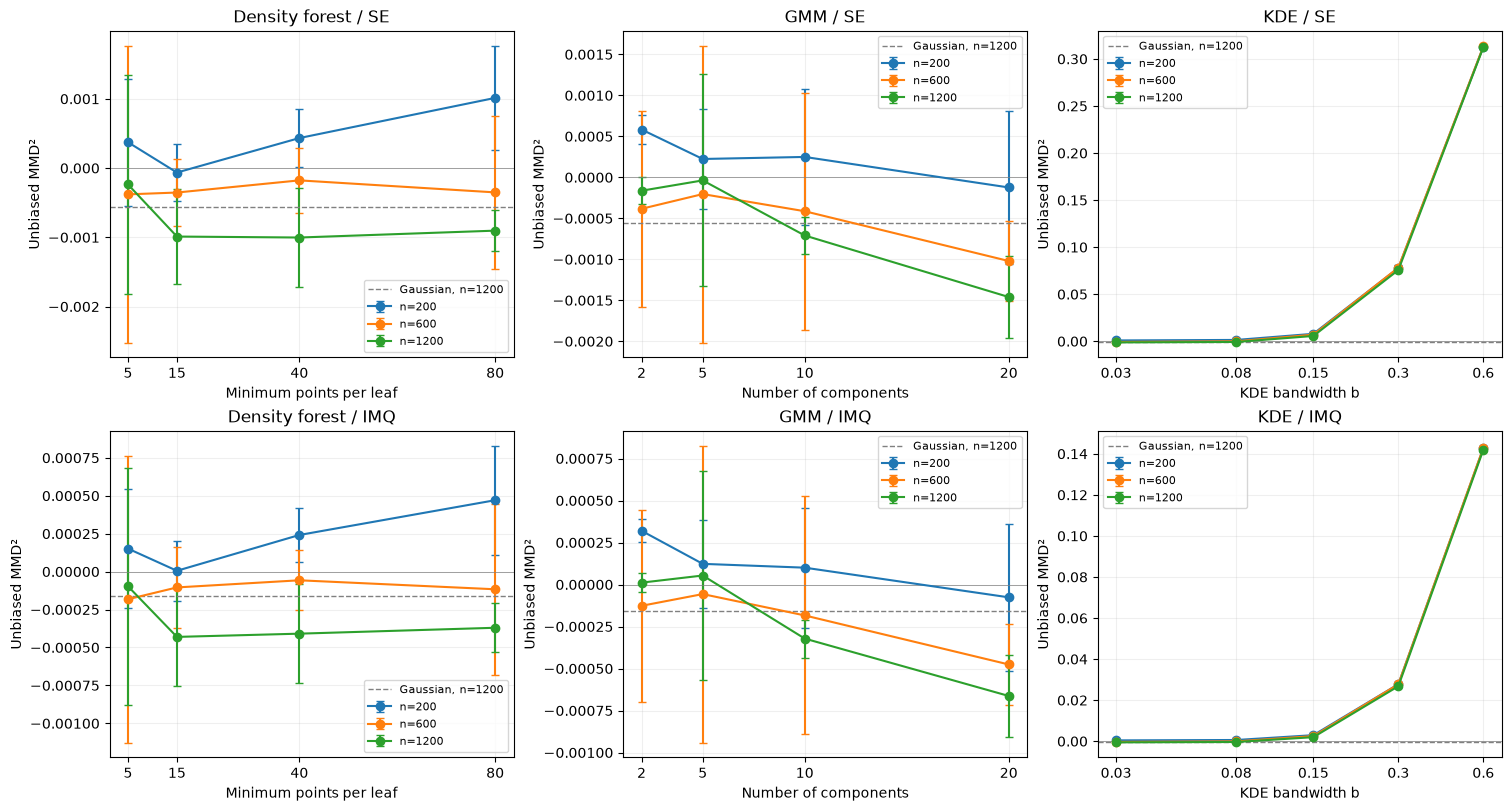

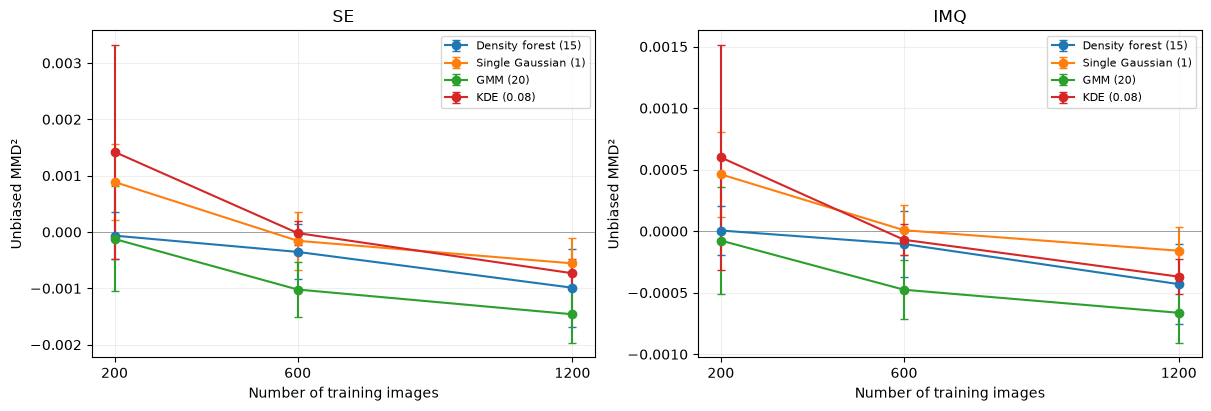

In [16]:
digit_families = ['Density forest', 'GMM', 'KDE']
digit_axis_labels = ['Minimum points per leaf', 'Number of components', 'KDE bandwidth b']
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for row, kernel in enumerate(('se', 'imq')):
    for col, (name, xlabel) in enumerate(zip(digit_families, digit_axis_labels)):
        ax = axes[row, col]
        parameters = digit_parameter_grid[name]
        for n_train in digit_train_sizes:
            values = [digit_summary[name, n_train, parameter, kernel] for parameter in parameters]
            means, stds = np.array(values).T
            ax.errorbar(parameters, means, yerr=stds, marker='o', capsize=3, label=f'n={n_train}')
        baseline = digit_summary['Single Gaussian', 1200, 1, kernel][0]
        ax.axhline(baseline, color='grey', linestyle='--', linewidth=1, label='Gaussian, n=1200')
        ax.axhline(0, color='grey', linewidth=0.5)
        ax.set(title=f'{name} / {kernel.upper()}', xlabel=xlabel, ylabel='Unbiased MMD²')
        if name == 'KDE':
            ax.set_xscale('log')
        ax.set_xticks(parameters, labels=[f'{p:g}' for p in parameters])
        ax.minorticks_off()
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.show()

digit_fixed_settings = {'Density forest': 15, 'Single Gaussian': 1, 'GMM': 20, 'KDE': 0.08}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, kernel in zip(axes, ('se', 'imq')):
    for name, parameter in digit_fixed_settings.items():
        means, stds = np.array([digit_summary[name, n, parameter, kernel] for n in digit_train_sizes]).T
        ax.errorbar(digit_train_sizes, means, yerr=stds, marker='o', capsize=3, label=f'{name} ({parameter})')
    ax.axhline(0, color='grey', linewidth=0.5)
    ax.set(title=kernel.upper(), xlabel='Number of training images', ylabel='Unbiased MMD²')
    ax.set_xticks(digit_train_sizes)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

## How the MMD bandwidth affects the digits comparison

These settings are fixed examples, not winners selected by combining the two
kernels. Each bandwidth curve uses the same generated images throughout. The
vertical line marks the training-distance median used above. The blue reference
compares two disjoint held-out sets of real images.

The second figure rescales the vertical axis after omitting KDE b=0.60, so
the smaller differences between the remaining models are visible. Smaller
bandwidths can expose errors that the training-median scale largely misses.


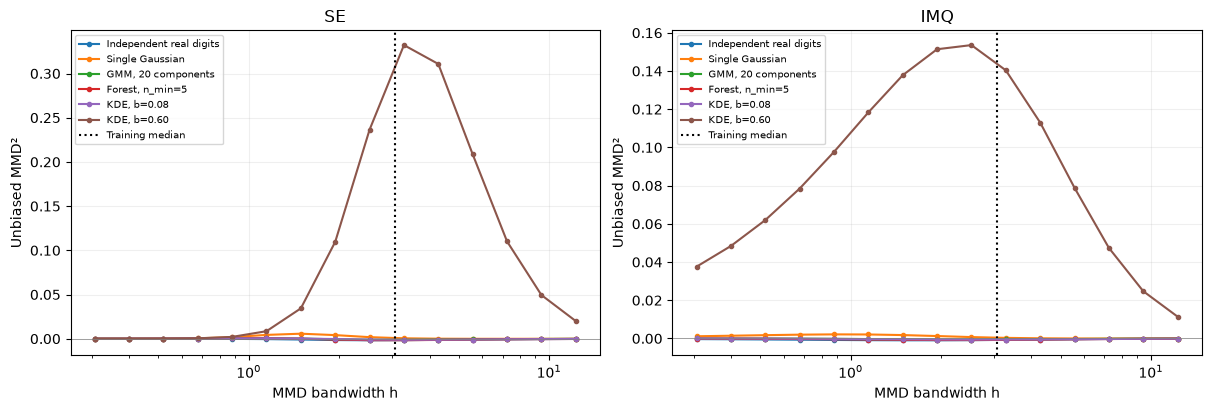

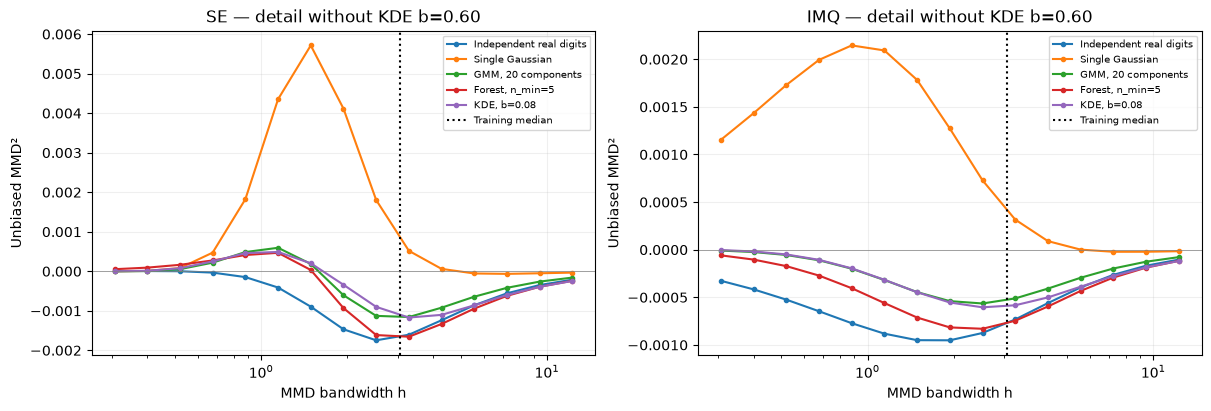

In [17]:
digit_examples = [
    ('Single Gaussian', 1, 'Single Gaussian'),
    ('GMM', 2, 'GMM, 2 components'),
    ('GMM', 20, 'GMM, 20 components'),
    ('Density forest', 5, 'Forest, n_min=5'),
    ('Density forest', 80, 'Forest, n_min=80'),
    ('KDE', 0.08, 'KDE, b=0.08'),
    ('KDE', 0.60, 'KDE, b=0.60'),
]
digit_example_samples = {}
with threadpool_limits(limits=1):
    for index, (name, parameter, label) in enumerate(digit_examples):
        digit_example_samples[label] = sample_digit_model(
            digit_models[name, parameter], len(digit_test), SEED + 200 + index
        )

digit_bandwidths = DIGIT_MMD_BANDWIDTH * np.geomspace(0.1, 4, 15)
digit_bandwidth_samples = {'Independent real digits': digit_reference}
for label in ['Single Gaussian', 'GMM, 20 components', 'Forest, n_min=5', 'KDE, b=0.08', 'KDE, b=0.60']:
    digit_bandwidth_samples[label] = digit_example_samples[label]
digit_bandwidth_results = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
with threadpool_limits(limits=1):
    for ax, kernel in zip(axes, ('se', 'imq')):
        for label, generated in digit_bandwidth_samples.items():
            values = [mmd2(digit_test, generated, bandwidth=h, kernel=kernel) for h in digit_bandwidths]
            digit_bandwidth_results[kernel, label] = values
            ax.plot(digit_bandwidths, values, '.-', label=label)
        ax.axvline(DIGIT_MMD_BANDWIDTH, color='black', linestyle=':', label='Training median')
        ax.axhline(0, color='grey', linewidth=0.5)
        ax.set(xscale='log', xlabel='MMD bandwidth h', ylabel='Unbiased MMD²', title=kernel.upper())
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7)
plt.show()


# The very noisy KDE dominates the first figure; inspect the other curves too.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, kernel in zip(axes, ('se', 'imq')):
    for label in digit_bandwidth_samples:
        if label != 'KDE, b=0.60':
            ax.plot(digit_bandwidths, digit_bandwidth_results[kernel, label], '.-', label=label)
    ax.axvline(DIGIT_MMD_BANDWIDTH, color='black', linestyle=':', label='Training median')
    ax.axhline(0, color='grey', linewidth=0.5)
    ax.set(xscale='log', xlabel='MMD bandwidth h', ylabel='Unbiased MMD²',
           title=f'{kernel.upper()} — detail without KDE b=0.60')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)
plt.show()


## Generated 8 × 8 images

Every image is displayed using the same grey scale, **vmin=0 and vmax=1**. This
saturates out-of-range intensities for display only; the MMD and classifier see
the unmodified 64-dimensional samples. Titles show the classifier's predicted
digit and maximum class probability. We display the first 16 samples after a
fixed random shuffle, without filtering by confidence or predicted class.

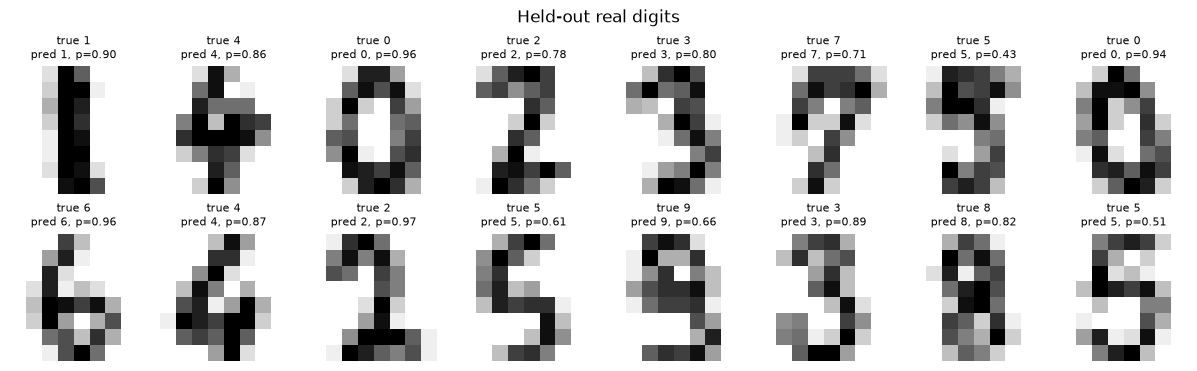

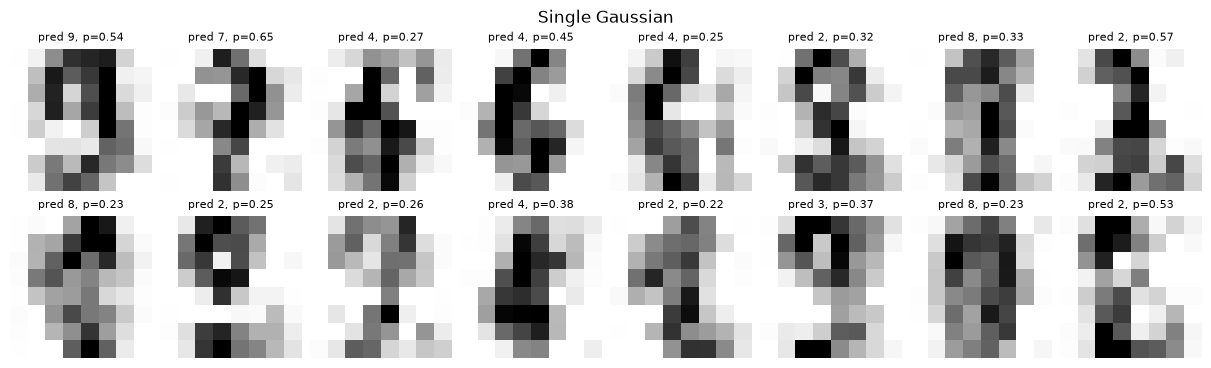

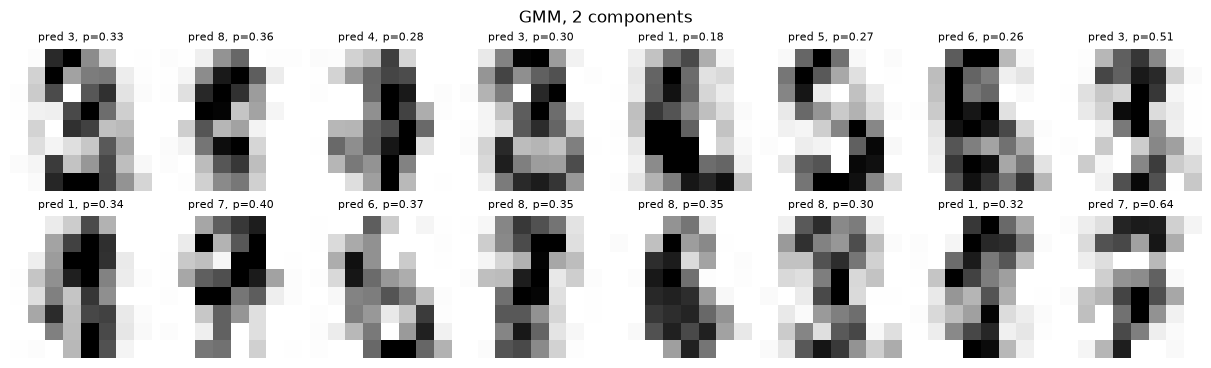

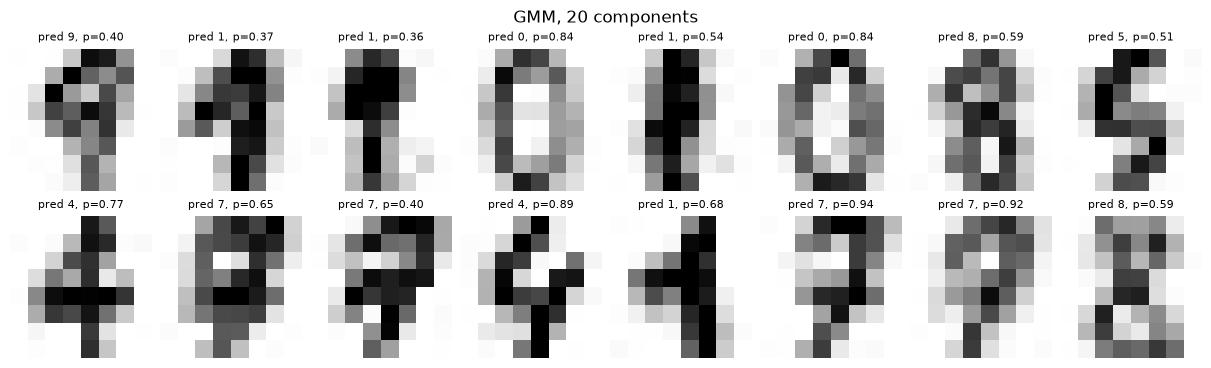

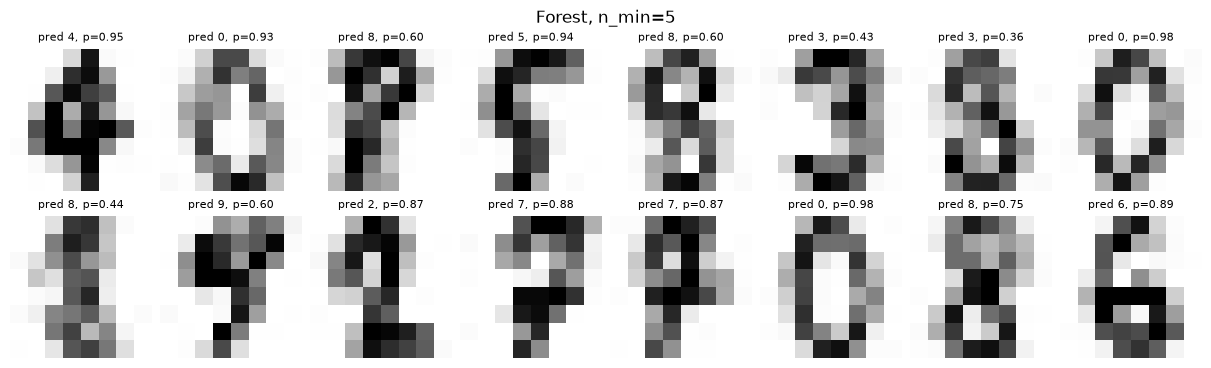

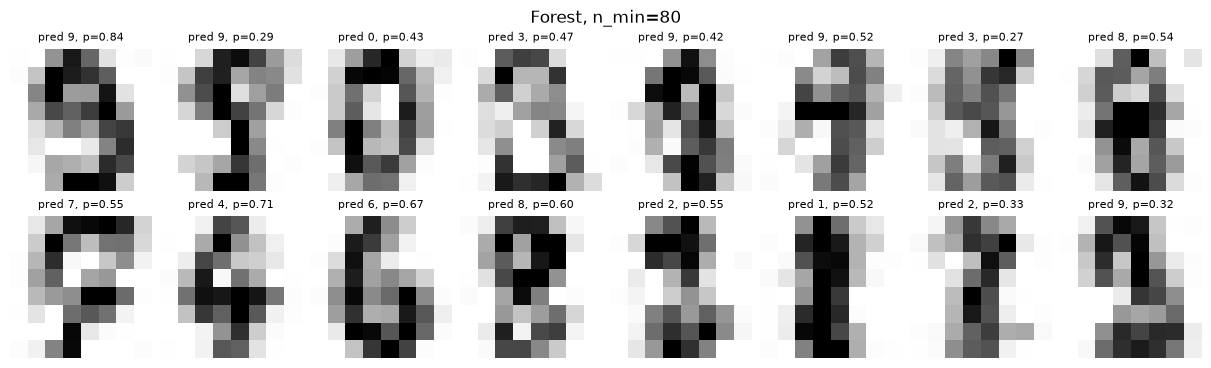

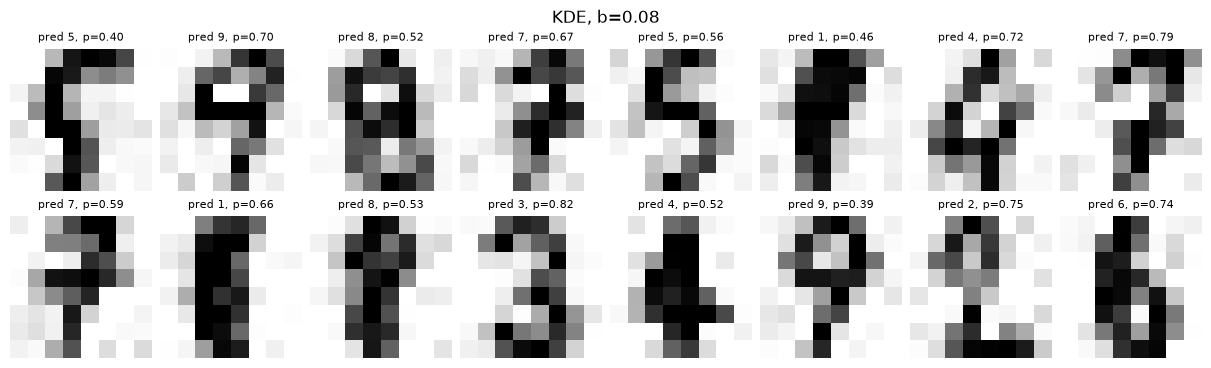

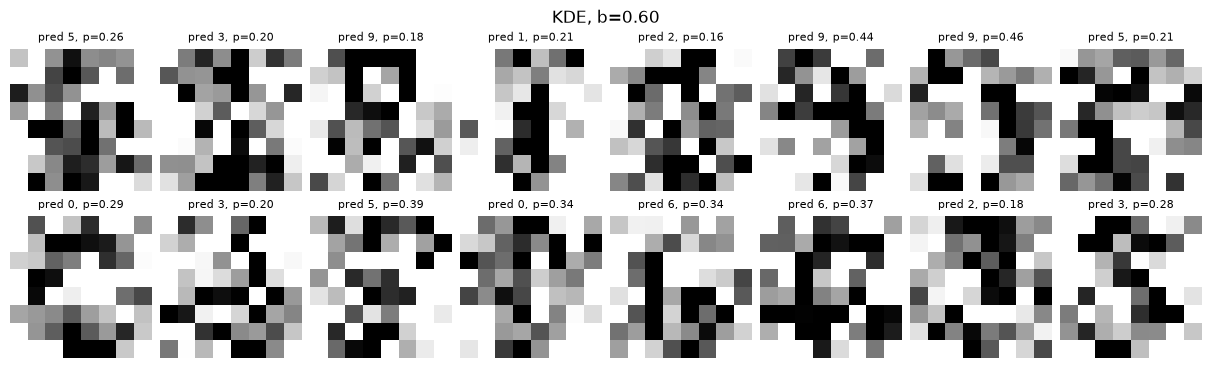

In [18]:
def show_digit_grid(images, title, true_labels=None, seed=SEED):
    probabilities = digit_classifier.predict_proba(images)
    predictions = digit_classifier.classes_[probabilities.argmax(axis=1)]
    confidence = probabilities.max(axis=1)
    indices = np.random.default_rng(seed).permutation(len(images))[:16]
    fig, axes = plt.subplots(2, 8, figsize=(12, 3.6), constrained_layout=True)
    fig.suptitle(title)
    for ax, index in zip(axes.ravel(), indices):
        ax.imshow(images[index].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1, interpolation='nearest')
        text = f'pred {predictions[index]}, p={confidence[index]:.2f}'
        if true_labels is not None:
            text = f'true {true_labels[index]}\n' + text
        ax.set_title(text, fontsize=8)
        ax.axis('off')
    plt.show()


show_digit_grid(digit_test, 'Held-out real digits', true_labels=digit_test_y)
for index, (_, _, label) in enumerate(digit_examples):
    show_digit_grid(digit_example_samples[label], label, seed=SEED + index)

## Checking Digit Balance

For each model, we generate 5000 new images and check how often each digit is predicted, as well as how many pass the confidence threshold. The bar charts show all predictions compared to the ideal 10% line and the real test data.

For models with at least 50% confident samples, we use a chi-square test to check if the ten digits are generated equally often. We also print the frequencies for just the confident samples to see how filtering changes the balance.

Keep in mind that these labels come from the classifier, so its own errors can affect the results. Because 5000 is a large sample size, even small imbalances look statistically significant, so we also report the largest deviation from 10%.

Model                   Confident   Max deviation   Uniform-test p
Single Gaussian             4.6%         11.5 pp  not interpreted
GMM, 2 components          11.4%          9.7 pp  not interpreted
GMM, 20 components         70.9%          1.1 pp           0.0274
Forest, n_min=5            72.3%          2.2 pp         1.01e-05
Forest, n_min=80           30.4%          6.2 pp  not interpreted
KDE, b=0.08                67.0%          1.0 pp            0.245
KDE, b=0.60                 0.6%          4.4 pp  not interpreted

Confident-subset percentages, classes 0 to 9:
Single Gaussian        [18.2  0.4 14.3 12.1 15.6  1.7  5.6  9.5  5.2 17.3]
GMM, 2 components      [15.   0.   7.   6.6 20.5  2.3  7.3 21.3  4.4 15.6]
GMM, 20 components     [12.7  4.1 10.5  8.2 12.5  8.2 13.6 11.6  7.9 10.7]
Forest, n_min=5        [10.7  8.7 10.4  9.9 11.8  9.1 10.2 11.4  8.7  9. ]
Forest, n_min=80       [ 7.8  2.5 11.2  8.7 17.1  7.8 16.9 15.1  4.1  8.8]
KDE, b=0.08            [ 9.9  7.1 10.5 10.1 12.8 

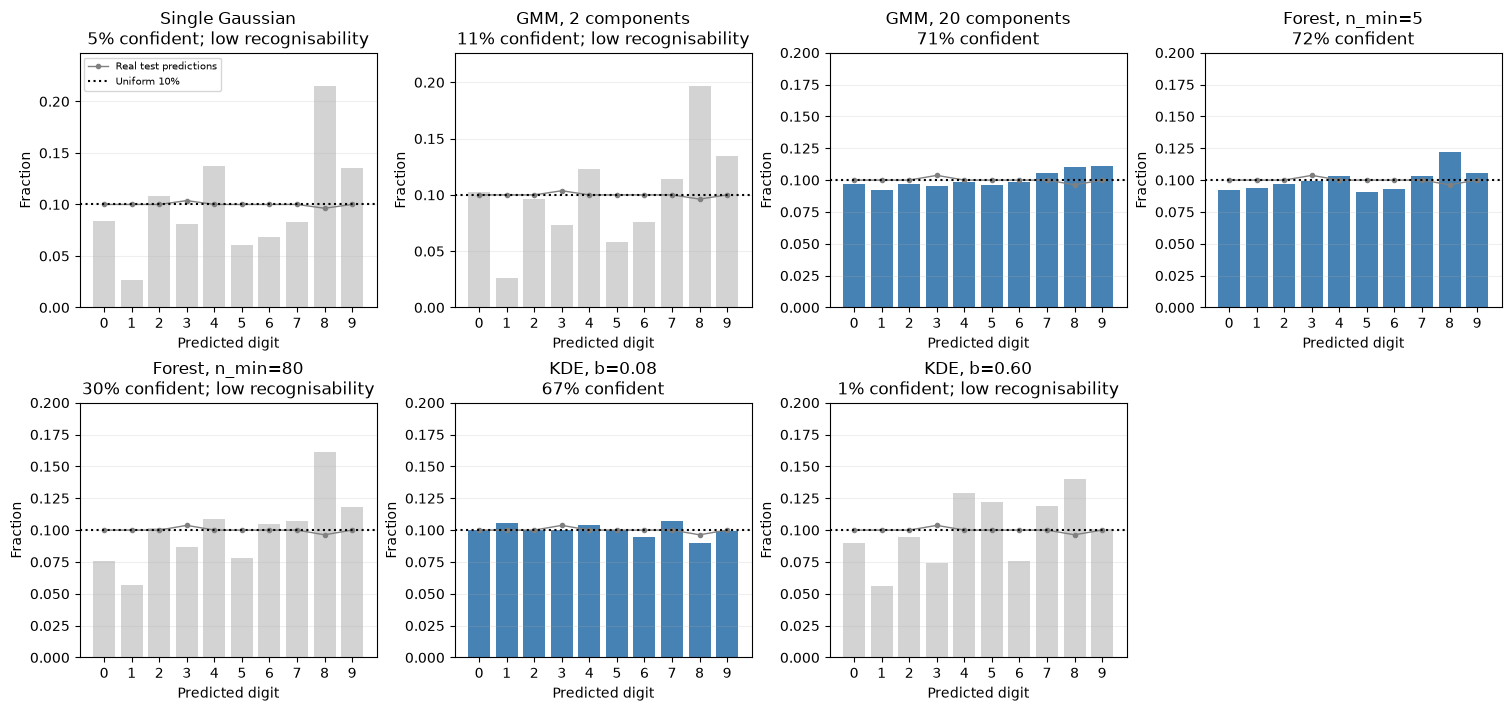

In [19]:
DIGIT_BALANCE_SAMPLES = 5000
digit_balance = []
with threadpool_limits(limits=1):
    for index, (name, parameter, label) in enumerate(digit_examples):
        images = sample_digit_model(digit_models[name, parameter], DIGIT_BALANCE_SAMPLES, SEED + 500 + index)
        probabilities = digit_classifier.predict_proba(images)
        predictions = digit_classifier.classes_[probabilities.argmax(axis=1)]
        confident = probabilities.max(axis=1) >= DIGIT_CONFIDENCE
        counts = np.bincount(predictions, minlength=10)
        confident_counts = np.bincount(predictions[confident], minlength=10)
        frequencies = counts / len(images)
        confident_frequencies = confident_counts / max(confident.sum(), 1)
        usable = confident.mean() >= 0.50
        p_value = float(chisquare(counts).pvalue) if usable else None
        digit_balance.append(dict(
            label=label, counts=counts.tolist(), frequencies=frequencies.tolist(),
            confident_frequencies=confident_frequencies.tolist(),
            coverage=float(confident.mean()), usable=bool(usable), p_value=p_value,
            max_deviation=float(np.max(np.abs(frequencies - 0.1))),
            out_of_range=float(np.mean((images < 0) | (images > 1))),
        ))

print(f"{'Model':<22} {'Confident':>10} {'Max deviation':>15} {'Uniform-test p':>16}")
for row in digit_balance:
    p_text = f"{row['p_value']:.3g}" if row['usable'] else 'not interpreted'
    print(f"{row['label']:<22} {row['coverage']:>9.1%} {100 * row['max_deviation']:>12.1f} pp {p_text:>16}")
print('\nConfident-subset percentages, classes 0 to 9:')
for row in digit_balance:
    print(f"{row['label']:<22}", np.round(100 * np.array(row['confident_frequencies']), 1))

real_frequencies = np.bincount(digit_real_predictions, minlength=10) / len(digit_test)
fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
for ax, row in zip(axes.ravel(), digit_balance):
    frequencies = np.array(row['frequencies'])
    ax.bar(np.arange(10), frequencies, color='steelblue' if row['usable'] else 'lightgrey')
    ax.plot(np.arange(10), real_frequencies, '.-', color='grey', linewidth=1, label='Real test predictions')
    ax.axhline(0.1, color='black', linestyle=':', label='Uniform 10%')
    status = f"{row['coverage']:.0%} confident"
    if not row['usable']:
        status += '; low recognisability'
    ax.set(title=row['label'] + '\n' + status, xlabel='Predicted digit', ylabel='Fraction',
           xticks=np.arange(10), ylim=(0, max(0.20, 1.15 * frequencies.max())))
    ax.grid(axis='y', alpha=0.2)
axes.ravel()[0].legend(fontsize=7)
axes.ravel()[-1].axis('off')
plt.show()

## Digits findings

**Classifier reference:** On the 270 real test images, the classifier reaches 97.78% accuracy. About 81.48% of real images pass the 0.60 confidence threshold, and all of those are classified correctly. This confirms the classifier is a reliable baseline, even though its confidence on generated images is only an approximation of visual quality.

**Single Gaussian and small GMM:** These simple models tend to blur different digit strokes together. Only 4.5% of single Gaussian samples and 11.6% of GMM(2) samples pass the confidence threshold. However, the single Gaussian still gets a near-zero SE MMD² score (-0.00056 at n=1200), which shows that a good MMD score at one bandwidth does not guarantee recognizable digits.

**Larger GMM:** Using 20 components produces much clearer digits, reaching 71.0% confident samples. Adding more training data also improves its mean MMD to -0.00148 (SE) and -0.00067 (IMQ) at n=1200. More components allow the model to capture different digit shapes locally, though covariance regularization is still needed in 64 dimensions.

**Density forest:** Small leaves preserve sharper strokes because they fit tighter local Gaussians. The 5-point leaf model reaches 72.4% confident samples, compared to just 30.0% for 80-point leaves, which average too many different images together. Since MMD scores across leaf sizes have overlapping error bars, the generated images and classifier scores show this difference much better than MMD alone.

**KDE:** A small bandwidth (b=0.08) performs well, giving 67.1% confident samples and a low MMD. With a large bandwidth (b=0.60), confident samples drop to 0.6% and mean MMD² jumps to 0.31228 (SE) and 0.14193 (IMQ) because independent noise is added across all 64 pixels. Keep in mind that very small bandwidths simply copy the training images, so a good score does not prove the model is generating new variations.

**Class proportions:** The stronger models generate all ten digits, though not all are perfectly balanced. KDE(0.08) is consistent with a uniform distribution (p=0.245, max deviation around 1.0%). GMM(20) has a similarly small deviation but a borderline p-value (p=0.0397), while the density forest shows a clearer imbalance (2.2% max deviation, p≈3.3×10⁻⁵).

**Confidence filtering:** Looking only at confident samples changes the class balance. For instance, the digit 1 makes up only 4.1% of the confident GMM(20) subset. This happens both because models generate some digits more clearly than others and because the classifier's confidence varies by digit.

**Training size and metric scale:** More training data generally helps the flexible models, though error bars across the three runs often overlap. The median heuristic bandwidth (h≈3.07) easily catches heavily noisy models like KDE(0.60), while smaller bandwidths are needed to spot finer differences. Slightly negative MMD² values are also normal here due to the finite sample size. Overall, combining MMD, visual inspection, and classifier scores gives a much fuller picture than relying on a single metric.

# **Group**: Emine Şevval Eş Uzunay - Erem Karalar - Berker Uğraş